# 1- Load it

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('data/nashville_home_sales.csv')
df.head()

,Sale ID,sale_date,Neighborhood,sqft,Bedrooms,bathrooms,Year Built,Sale Price,listing_agent
0,100261,11/19/2023,BELLEVUE,1470,3.0,2.0,2015.0,"$403,600",Benchmark
1,104133,03/19/2024,Donelson,2469,3.0,3.0,2023.0,"$501,600",Compass
2,100080,04/06/2024,Germantown,3229,3.0,3.0,1982.0,"$1,178,600",Onward
3,102992,03/07/2024,Sylvan Park,1467,4.0,2.0,2019.0,"$592,900",Benchmark
4,103700,09/01/2024,12 SOUTH,2620,3.0,3.0,1926.0,"$1,028,400",Hays & Co


# 2-Four things to run before you do anything else
.shape .info() .describe() .head()

In [2]:
df.shape

(8440, 9)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sale ID        8440 non-null   int64  
 1   sale_date      8440 non-null   str    
 2   Neighborhood   8440 non-null   str    
 3   sqft           8440 non-null   int64  
 4   Bedrooms       7999 non-null   float64
 5   bathrooms      8254 non-null   float64
 6   Year Built     8171 non-null   float64
 7   Sale Price     8440 non-null   str    
 8   listing_agent  8343 non-null   str    
dtypes: float64(3), int64(2), str(4)
memory usage: 593.6 KB


In [4]:
df.describe()

,Sale ID,sqft,Bedrooms,bathrooms,Year Built
count,8440.000000,8440.000000,7999.000000,8254.000000,8171.000000
mean,104099.358294,1996.506280,3.096512,2.455173,1972.358218
std,2365.968315,3747.831299,0.929867,0.795519,30.456186
min,100000.000000,600.000000,1.000000,1.000000,1920.000000
25%,102051.750000,1443.750000,2.000000,2.000000,1946.000000
50%,104092.500000,1851.000000,3.000000,2.000000,1972.000000
75%,106151.250000,2272.000000,4.000000,3.000000,1999.000000
max,108199.000000,99999.000000,6.000000,5.000000,2024.000000


# 3- Error Check

What is the average sale price

In [5]:
df['Sale Price']=df['Sale Price'].str.replace('$','').str.replace(',','').astype(float)

df['Sale Price'].mean()

np.float64(538504.9763033176)

# 5- Cleaning the Data

In [6]:
list(df.columns)

['Sale ID',
 'sale_date',
 'Neighborhood',
 'sqft ',
 'Bedrooms',
 'bathrooms',
 'Year Built',
 'Sale Price',
 'listing_agent']

In [7]:
# df.columns=df.columns.str.strip().str.lower().str.replace(' ','_')
# list(df.columns)

In [8]:
def snake_case(df):
    return df.columns.str.strip().str.lower().str.replace(' ','_')

df.columns=snake_case(df)

list(df.columns)

['sale_id',
 'sale_date',
 'neighborhood',
 'sqft',
 'bedrooms',
 'bathrooms',
 'year_built',
 'sale_price',
 'listing_agent']

# 6- Dates

In [9]:
df['sale_date']=pd.to_datetime(df['sale_date'])

df['sale_date']

0      2023-11-19
1      2024-03-19
2      2024-04-06
3      2024-03-07
4      2024-09-01
          ...    
8435   2024-06-15
8436   2023-04-07
8437   2024-01-09
8438   2023-05-26
8439   2024-05-01
Name: sale_date, Length: 8440, dtype: datetime64[us]

# 7-Duplicates

In [10]:
df.duplicated().sum()

np.int64(240)

In [11]:
before=len(df)
df.drop_duplicates(inplace=True)
after=len(df)

print(before, after)

8440 8200


# 8- Missing Values

In [12]:
df.isna().sum()

sale_id            0
sale_date          0
neighborhood       0
sqft               0
bedrooms         430
bathrooms        180
year_built       260
sale_price         0
listing_agent     95
dtype: int64

In [13]:
df['bedrooms']=df['bedrooms'].fillna(df['bedrooms'].mean()) # mean imputation

# 9-Categorical Data

In [14]:
df['neighborhood'].value_counts()

neighborhood
Antioch             1001
East Nashville       997
Madison              856
Donelson             756
The Nations          756
Bellevue             601
Sylvan Park          600
Green Hills          567
12 South             504
Germantown           409
ANTIOCH              103
MADISON               88
EAST NASHVILLE        76
 East Nashville       69
THE NATIONS           69
DONELSON              67
 Antioch              61
SYLVAN PARK           60
GREEN HILLS           58
BELLEVUE              55
 Donelson             51
 Madison              49
12 SOUTH              47
 Bellevue             47
 The Nations          42
 Sylvan Park          40
 Green Hills          36
GERMANTOWN            30
 Germantown           30
 12 South             28
 THE NATIONS           9
 DONELSON              6
 SYLVAN PARK           6
 12 SOUTH              5
 MADISON               5
 EAST NASHVILLE        5
 ANTIOCH               4
 BELLEVUE              4
 GREEN HILLS           3
Name: count,

In [15]:
df['neighborhood']=df['neighborhood'].str.strip().str.title()
df['neighborhood'].value_counts()

neighborhood
Antioch           1169
East Nashville    1147
Madison            998
Donelson           880
The Nations        876
Bellevue           707
Sylvan Park        706
Green Hills        664
12 South           584
Germantown         469
Name: count, dtype: int64

# 10-Outliers

In [16]:
df['sqft'].describe()

count     8200.000000
mean      2001.193415
std       3800.862922
min        600.000000
25%       1441.750000
50%       1850.000000
75%       2272.000000
max      99999.000000
Name: sqft, dtype: float64

In [17]:
df[df['sqft']> df['sqft'].mean()+(df['sqft'].std()*2)]

,sale_id,sale_date,neighborhood,sqft,bedrooms,bathrooms,year_built,sale_price,listing_agent
755,106731,2024-07-19,East Nashville,99999,2.000000,1.0,1928.0,408100.0,Zeitlin
811,104832,2023-10-05,12 South,99999,3.000000,3.0,2021.0,552900.0,Zeitlin
1241,106092,2024-11-19,Sylvan Park,99999,4.000000,4.0,1954.0,650500.0,Compass
2046,101114,2023-11-21,Bellevue,99999,4.000000,3.0,1960.0,354400.0,Benchmark
3130,102618,2024-02-17,Green Hills,99999,5.000000,4.0,1957.0,753800.0,Hays & Co
3604,104257,2023-12-13,Madison,99999,4.000000,2.0,1986.0,462000.0,Onward
3942,107535,2024-08-18,Antioch,99999,4.000000,3.0,2012.0,317700.0,Onward
4024,103121,2024-07-29,East Nashville,99999,3.000000,2.0,1964.0,365100.0,Hays & Co
4314,106212,2023-02-06,Sylvan Park,99999,3.097941,3.0,1944.0,379600.0,Zeitlin
5170,107000,2024-07-25,East Nashville,99999,4.000000,2.0,2019.0,448000.0,Zeitlin


In [41]:
df['price_per_sqft']=df['sale_price']/df['sqft']

# 11- Ask a Question

In [44]:
df.groupby('neighborhood')['price_per_sqft'].mean().sort_values(ascending=False)

neighborhood
Green Hills       524.104146
12 South          451.579769
Germantown        432.817630
Sylvan Park       352.145046
The Nations       308.884365
East Nashville    286.557485
Bellevue          253.544247
Donelson          233.129495
Madison           199.624438
Antioch           181.458125
Name: price_per_sqft, dtype: float64

In [45]:
df.groupby('neighborhood')['sale_price'].mean().sort_values(ascending=False)

neighborhood
Green Hills       949223.945783
12 South          820368.321918
Germantown        772211.940299
Sylvan Park       629481.161473
The Nations       558679.908676
East Nashville    513438.535310
Bellevue          452613.012730
Donelson          413508.636364
Madison           356980.460922
Antioch           324935.671514
Name: sale_price, dtype: float64

<Axes: xlabel='price_per_sqft', ylabel='neighborhood'>

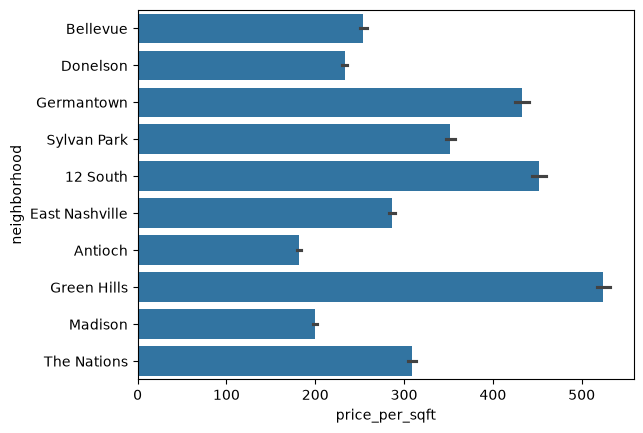

In [43]:
import seaborn as sns
sns.barplot(df,x='price_per_sqft',y='neighborhood')